# Babar Azam in T20 Internationals: What 131 Innings Say

**Question:** How does Babar Azam's T20I scoring vary with context (chasing or setting, home or away, opposition, match result), how does it develop within an innings, and how has it changed from 2016 to 2026?

**Data:** Ball-by-ball T20 international match files from [Cricsheet](https://cricsheet.org). The final dataset has one row per innings in which he faced at least one ball: 131 innings and 3,410 balls faced.

**Approach:** Parse the raw JSON into a per-innings table, engineer features (phase totals, required strike rate, home/away), then explore with distributions, group comparisons and a simple regression.

**Contents**
1. Setup and helper functions
2. Building the dataset
3. Overall scoring profile
4. Scoring within an innings
5. Context: chasing vs setting, home vs away, win vs loss, opposition
6. Career trend
7. Score vs balls faced
8. Conclusions and limitations

## 1. Setup and helper functions
Chart styling is set once here so every figure matches. The helper functions read the Cricsheet JSON structure and return a batter's runs and balls faced, per over and per innings.

In [1]:
# Imports
import matplotlib.pyplot as plt
import json
import glob
import pandas as pd
import seaborn as sn
import numpy as np
import os
import matplotlib_inline.backend_inline

In [2]:
plt.rcParams['figure.facecolor'] = '#F8F8F8'
plt.rcParams['axes.facecolor'] = '#F8F8F8'
plt.rcParams['text.color'] = '#4a4a4a'
plt.rcParams['axes.labelcolor'] = '#4a4a4a'
plt.rcParams['xtick.color'] = '#4a4a4a'
plt.rcParams['ytick.color'] = '#4a4a4a'
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.titlelocation'] = 'left'
plt.rcParams['axes.titlepad'] = 15
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.color'] = '#E0E0E0'
plt.rcParams['grid.linewidth'] = 0.5
plt.rcParams['grid.alpha'] = 0.7
plt.rcParams['axes.axisbelow'] = True

In [3]:
pd.set_option('display.float_format', '{:.3f}'.format)

In [4]:
# To get batsman's score for a particular over
def get_batsman_runs_for_over(data_loaded,batsman,inning,over):
    over = data_loaded['innings'][inning]['overs'][over]
    runs = 0 
    for delivery in over['deliveries']:
        if delivery['batter'] == batsman:
            runs = runs + delivery['runs']['batter']
    return runs

In [5]:
#To get batsman's score for all overs
def get_batsman_runs_by_overs(data_loaded,batsman,inning):
    overs = data_loaded['innings'][inning]['overs']
    runs = {}
    for over in overs:
        over_number = over['over']
        runs[over_number] = get_batsman_runs_for_over(data_loaded,batsman, inning, over_number)
    return runs

In [6]:
#To get batsman's played balls for a particular over
def get_batsman_balls_for_over(data_loaded,batsman,inning,over):
    over = data_loaded['innings'][inning]['overs'][over]
    balls = 0 
    
    for delivery in over['deliveries']:
        if delivery['batter'] == batsman and delivery['runs']['extras'] == 0:
            balls = balls+1
        elif delivery['batter'] == batsman and delivery['runs']['extras'] != 0:
            if 'legbyes' in delivery['extras'].keys(): 
                balls = balls+1
    return balls 

In [7]:
#To get batsman's played balls for all overs
def get_batsman_balls_by_overs(data_loaded,batsman,inning):
    overs = data_loaded['innings'][inning]['overs']
    balls = {}
    for over in overs:
        over_number = over['over']
        balls[over_number] = get_batsman_balls_for_over(data_loaded,batsman, inning, over_number)
    return balls

In [8]:
#To get player name from hexacode of palyer registry
def player_name_from_hexa(hexa,data_loaded):
    name = 'None'
    players = data_loaded['info']['registry']['people']
    players_dict = {hexa_val:name for name, hexa_val in players.items()}
    
    if hexa in players_dict.keys():
        name = players_dict[hexa]
    return name

In [ ]:
def create_player_table_by_name_for_overs_t20(player_name,team_name):
    rows = []
    team_name.title()
    file_path_list = list(glob.glob(f't20s_json/*.json'))
    for file_path in file_path_list:
        with open(file_path, "r") as f:
            data = f.read()
            new_data_loaded = json.loads(data)
            innings_data = new_data_loaded['innings']
            has_second_inning = len(innings_data) > 1
        
        row = {
               'file_name':os.path.basename(file_path),
                #'balls per over': int(new_data_loaded['info']['balls_per_over']),
                'dates': new_data_loaded['info']['dates'][0],
                #'event name': new_data_loaded['info'].get('event', {}).get('name', None),
                'outcome': new_data_loaded['info'].get('outcome', {}).get('winner', None),
                'outcome_by_wickets': new_data_loaded['info'].get('outcome', {}).get('by', {}).get('wickets'),
                'outcome_by_runs': new_data_loaded['info'].get('outcome', {}).get('by', {}).get('runs'),
                'chasing': 0 if new_data_loaded['innings'][0]['team'] == team_name else 1,
                'target(runs)' : new_data_loaded['innings'][1].get('target',{}).get('runs') if has_second_inning ==True else None,
                'target(to_acheive_in_overs)' : new_data_loaded['innings'][1].get('target',{}).get('overs') if has_second_inning ==True else None,
                'match overs': int(new_data_loaded['info']['overs']),
                'city' : new_data_loaded['info'].get('city',None),
                'venue': new_data_loaded['info']['venue'],
                'balls_played_first_inning': sum(get_batsman_balls_by_overs(new_data_loaded,player_name, 0).values()),
                'balls_played_second_inning': sum(get_batsman_balls_by_overs(new_data_loaded,player_name, 1).values()) if has_second_inning ==True else 0,
                'runs_first_inning': sum(get_batsman_runs_by_overs(new_data_loaded,player_name, 0).values()),
                'runs_second_inning': sum(get_batsman_runs_by_overs(new_data_loaded,player_name, 1).values())if has_second_inning == True else 0,'Player_name' : player_name,
                'playing_for':new_data_loaded['info']['teams'][0] if team_name in new_data_loaded['info']['teams'][0] else new_data_loaded['info']['teams'][1],
                'against':new_data_loaded['info']['teams'][0] if team_name not in new_data_loaded['info']['teams'][0] else new_data_loaded['info']['teams'][1]
            }
        
        rows.append(row)

        if row['balls_played_first_inning'] > 0:
            inn = 0
        
        elif row['balls_played_second_inning'] > 0 and has_second_inning:
            inn = 1
        
        else:
            continue
        
        for ov in range(0,20):
            row[f"over_{ov+1}_balls"]=0
        for ov in range(0,len(new_data_loaded['innings'][inn]['overs'])):
            balls = get_batsman_balls_for_over(new_data_loaded,player_name,inn,ov)
            row[f"over_{ov+1}_balls"] = balls

        for ov in range(0,20):
            row[f"over_{ov+1}_runs"]=0
        for ov in range(0,len(new_data_loaded['innings'][inn]['overs'])):
            runs = get_batsman_runs_for_over(new_data_loaded,player_name,inn,ov)
            row[f"over_{ov+1}_runs"] = runs

    player_table = pd.DataFrame(rows)
    player_table['score'] = player_table['runs_first_inning'] + player_table['runs_second_inning']
    player_table['balls'] = player_table['balls_played_first_inning'] + player_table['balls_played_second_inning']
    player_table.drop(['balls_played_first_inning', 'balls_played_second_inning', 'runs_first_inning', 'runs_second_inning'],axis=1,inplace=True)
    player_table = player_table[player_table['balls'] != 0]
    player_table['dates'] = pd.to_datetime(player_table['dates'])
    return player_table

In [10]:
def get_player_per_over_strike_rate_20_overs(over_table):

    player_overs = over_table.loc[:,"over_1_balls":"over_20_balls"]
    player_runs = over_table.loc[:,"over_1_runs":"over_20_runs"]
    player_overs.columns = player_overs.columns.str.replace("_balls","")
    player_runs.columns = player_runs.columns.str.replace("_runs","")
    player_per_over_sr = (player_runs / player_overs) * 100
    player_per_over_sr["dates"] = over_table["dates"]
    player_per_over_sr['player_name'] = over_table['Player_name']

    return player_per_over_sr

In [11]:
def transform_to_batsman_overs(df):
    
    # identify columns
    ball_cols = [col for col in df.columns if "over_" in col and "_balls" in col]
    run_cols  = [col for col in df.columns if "over_" in col and "_runs" in col]
    
    max_overs = len(ball_cols)
    
    new_rows = []
    
    for _, row in df.iterrows():
        
        # find entry over
        entry = None
        for i in range(max_overs):
            if row[ball_cols[i]] > 0:
                entry = i
                break
        
        # if player never batted
        if entry is None:
            new_rows.append(row)
            continue
        
        # extract new sequences
        new_ball_values = row[ball_cols].values[entry:]
        new_run_values  = row[run_cols].values[entry:]
        
        # create new row dictionary
        new_row = row.copy()
        
        # reset all overs to zero first
        for col in ball_cols:
            new_row[col] = 0
        for col in run_cols:
            new_row[col] = 0
        
        # fill new batsman overs
        for i in range(len(new_ball_values)):
            new_row[f"over_{i+1}_balls"] = new_ball_values[i]
            new_row[f"over_{i+1}_runs"]  = new_run_values[i]
        
        new_rows.append(new_row)
    
    # convert back to DataFrame
    new_df = pd.DataFrame(new_rows)
    
    return new_df

In [12]:
def reshape_strike_rate(df, date_col='dates', over_prefix='over_'):
    # Takes strike rate dataframe
    df_long = df.melt(
        id_vars=[date_col,'player_name'],
        value_vars=[col for col in df.columns if col.startswith(over_prefix)],
        var_name='over',
        value_name='strike_rate'
    )
    
    # clean
    #df_long = df_long.dropna()
    df_long['over'] = df_long['over'].str.replace(over_prefix, '').astype(int)

    return df_long

## 2. Building the dataset
`create_player_table_by_name_for_overs_t20` loops over every match file and builds one row per innings with: date, venue, opposition, result, target, runs and balls for each of the 20 overs, total score and balls faced. Matches where he did not bat are dropped.

**Definitions used below**
- **Phases:** powerplay = overs 1–6, middle = overs 7–15, death = overs 16–20.
- **Required strike rate:** target ÷ (overs available × 6) × 100.
- **Score as % of target:** his score ÷ the target he was chasing.
- **Home/away:** "home" if the match city is in `pakistan_cities.csv`, otherwise "away".
- **Setting / chasing:** whether Pakistan batted first or second.

In [13]:
babar_player_table_t20 = create_player_table_by_name_for_overs_t20('Babar Azam','Pakistan')
babar_player_table_t20= babar_player_table_t20[babar_player_table_t20['against'] != "ICC World XI"]
babar_player_table_t20['against']=babar_player_table_t20['against'].replace('United States of America', 'US')

In [14]:
babar_player_table_t20['required_strike_rate'] =(babar_player_table_t20['target(runs)']/(babar_player_table_t20['target(to_acheive_in_overs)']*6)) * 100

In [15]:
babar_player_table_t20['score_as_percent_of_target'] = (babar_player_table_t20['score'] / babar_player_table_t20['target(runs)']) * 100

In [16]:
babar_player_table_t20["player's_strike_rate"] = (babar_player_table_t20['score'] / babar_player_table_t20["balls"]) * 100

In [17]:
babar_player_table_t20['score_in_death_overs'] = babar_player_table_t20.loc[:,'over_16_runs':'over_20_runs'].sum(axis=1)
babar_player_table_t20['balls_in_death_overs'] = babar_player_table_t20.loc[:,'over_16_balls':'over_20_balls'].sum(axis=1)

In [18]:
babar_player_table_t20['score_in_power_play'] = babar_player_table_t20.loc[:,'over_1_runs':'over_6_runs'].sum(axis=1)
babar_player_table_t20['balls_in_power_play'] = babar_player_table_t20.loc[:,'over_1_balls':'over_6_balls'].sum(axis=1)

In [19]:
babar_player_table_t20['score_in_middle_overs'] = babar_player_table_t20.loc[:,'over_7_runs':'over_15_runs'].sum(axis=1)
babar_player_table_t20['balls_in_middle_overs'] = babar_player_table_t20.loc[:,'over_7_balls':'over_15_balls'].sum(axis=1)

In [20]:

babar_player_table_t20.insert(2,'year',babar_player_table_t20['dates'].dt.year)
babar_player_table_t20.insert(3,"month",babar_player_table_t20["dates"].dt.month)
babar_player_table_t20.insert(4,'day',babar_player_table_t20["dates"].dt.day)

In [21]:
babar_player_table_t20

,file_name,dates,year,month,day,outcome,outcome_by_wickets,outcome_by_runs,chasing,target(runs),...,balls,required_strike_rate,score_as_percent_of_target,player's_strike_rate,score_in_death_overs,balls_in_death_overs,score_in_power_play,balls_in_power_play,score_in_middle_overs,balls_in_middle_overs
24,1050217.json,2016-09-23,2016,9,23,Pakistan,9.000,NaN,1,116.000,...,36,96.667,47.414,152.778,0.000,0.000,7.000,6.000,48.000,30.000
25,1050219.json,2016-09-24,2016,9,24,Pakistan,NaN,16.000,0,161.000,...,18,134.167,11.801,105.556,0.000,0.000,11.000,11.000,8.000,7.000
26,1050221.json,2016-09-27,2016,9,27,Pakistan,8.000,NaN,1,104.000,...,24,86.667,25.962,112.500,0.000,0.000,2.000,3.000,25.000,21.000
46,1077947.json,2017-03-26,2017,3,26,Pakistan,6.000,NaN,1,112.000,...,29,93.333,25.893,100.000,0.000,0.000,4.000,3.000,25.000,26.000
47,1077948.json,2017-03-30,2017,3,30,Pakistan,NaN,3.000,0,133.000,...,28,110.833,20.301,96.429,0.000,0.000,24.000,23.000,3.000,5.000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4273,1512763.json,2026-02-24,2026,2,24,England,2.000,NaN,0,165.000,...,24,137.500,15.152,104.167,0.000,0.000,10.000,6.000,15.000,18.000
4415,1519636.json,2026-01-29,2026,1,29,Pakistan,NaN,22.000,0,169.000,...,20,140.833,14.201,120.000,0.000,0.000,0.000,0.000,24.000,20.000
4416,1519637.json,2026-01-31,2026,1,31,Pakistan,NaN,90.000,0,199.000,...,5,165.833,1.005,40.000,0.000,0.000,0.000,1.000,2.000,4.000
4417,1519638.json,2026-02-01,2026,2,1,Pakistan,NaN,111.000,0,208.000,...,36,173.333,24.038,138.889,10.000,8.000,7.000,6.000,33.000,22.000


## 3. Overall scoring profile
Across 131 innings: **mean 33.3, median 27, standard deviation 27.9, highest 122**. The mean sits above the median, which points to a right-skewed distribution: many modest scores and a few very large ones.

In [22]:
babar_player_table_t20.describe()

,dates,year,month,day,outcome_by_wickets,outcome_by_runs,chasing,target(runs),target(to_acheive_in_overs),match overs,...,balls,required_strike_rate,score_as_percent_of_target,player's_strike_rate,score_in_death_overs,balls_in_death_overs,score_in_power_play,balls_in_power_play,score_in_middle_overs,balls_in_middle_overs
count,131,131.000,131.000,131.000,68.000,61.000,131.000,131.000,131.000,131.000,...,131.000,131.000,131.000,131.000,131.000,131.000,131.000,131.000,131.000,131.000
mean,2022-01-01 01:27:56.335877,2021.450,7.122,16.046,6.176,35.869,0.504,160.328,19.817,20.000,...,26.031,135.357,20.645,108.821,3.519,2.145,12.618,10.679,17.191,13.206
min,2016-09-07 00:00:00,2016.000,1.000,1.000,2.000,1.000,0.000,91.000,7.000,20.000,...,1.000,75.833,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
25%,2019-12-16 12:00:00,2019.500,4.000,8.000,5.000,9.000,0.000,137.500,20.000,20.000,...,10.000,115.833,5.886,85.165,0.000,0.000,3.000,4.000,0.000,0.000
50%,2022-08-28 00:00:00,2022.000,9.000,16.000,6.000,27.000,1.000,160.000,20.000,20.000,...,25.000,135.833,18.785,114.286,0.000,0.000,11.000,11.000,15.000,15.000
75%,2024-03-06 00:00:00,2024.000,10.000,24.000,7.000,48.000,1.000,184.000,20.000,20.000,...,40.500,155.833,33.113,141.667,1.000,2.000,21.000,16.500,30.500,24.000
max,2026-02-24 00:00:00,2026.000,12.000,31.000,10.000,155.000,1.000,233.000,20.000,20.000,...,66.000,223.810,59.804,209.091,46.000,20.000,45.000,25.000,71.000,35.000
std,NaN,2.617,3.684,9.234,1.923,33.604,0.502,32.020,1.317,0.000,...,17.421,27.327,16.124,47.245,8.006,4.368,10.575,6.867,18.008,11.930


In [23]:
babar_player_table_t20['result'] = (
    babar_player_table_t20['outcome']
    .eq('Pakistan')
    .map({True: 'win', False: 'lose'})
)

In [24]:
babar_player_table_t20_set_for_batsman = transform_to_batsman_overs(babar_player_table_t20)
babar_player_table_t20_set_for_batsman_strike_rate= get_player_per_over_strike_rate_20_overs(babar_player_table_t20_set_for_batsman)
babar_player_table_t20_set_for_batsman_strike_rate_reshaped = reshape_strike_rate(babar_player_table_t20_set_for_batsman_strike_rate)

## 4. Scoring within an innings
In this section, **"over" means the over of his own innings** (over 1 = the first over he faced), not the match over. This lets us see how he builds an innings regardless of when he walks in.

### Strike rate distribution by over
**Takeaway:** The first overs show a wide spread with many low strike rates, as he settles. The distribution moves right and gets flatter later in the innings, but later overs have far fewer observations, so those shapes are less reliable.

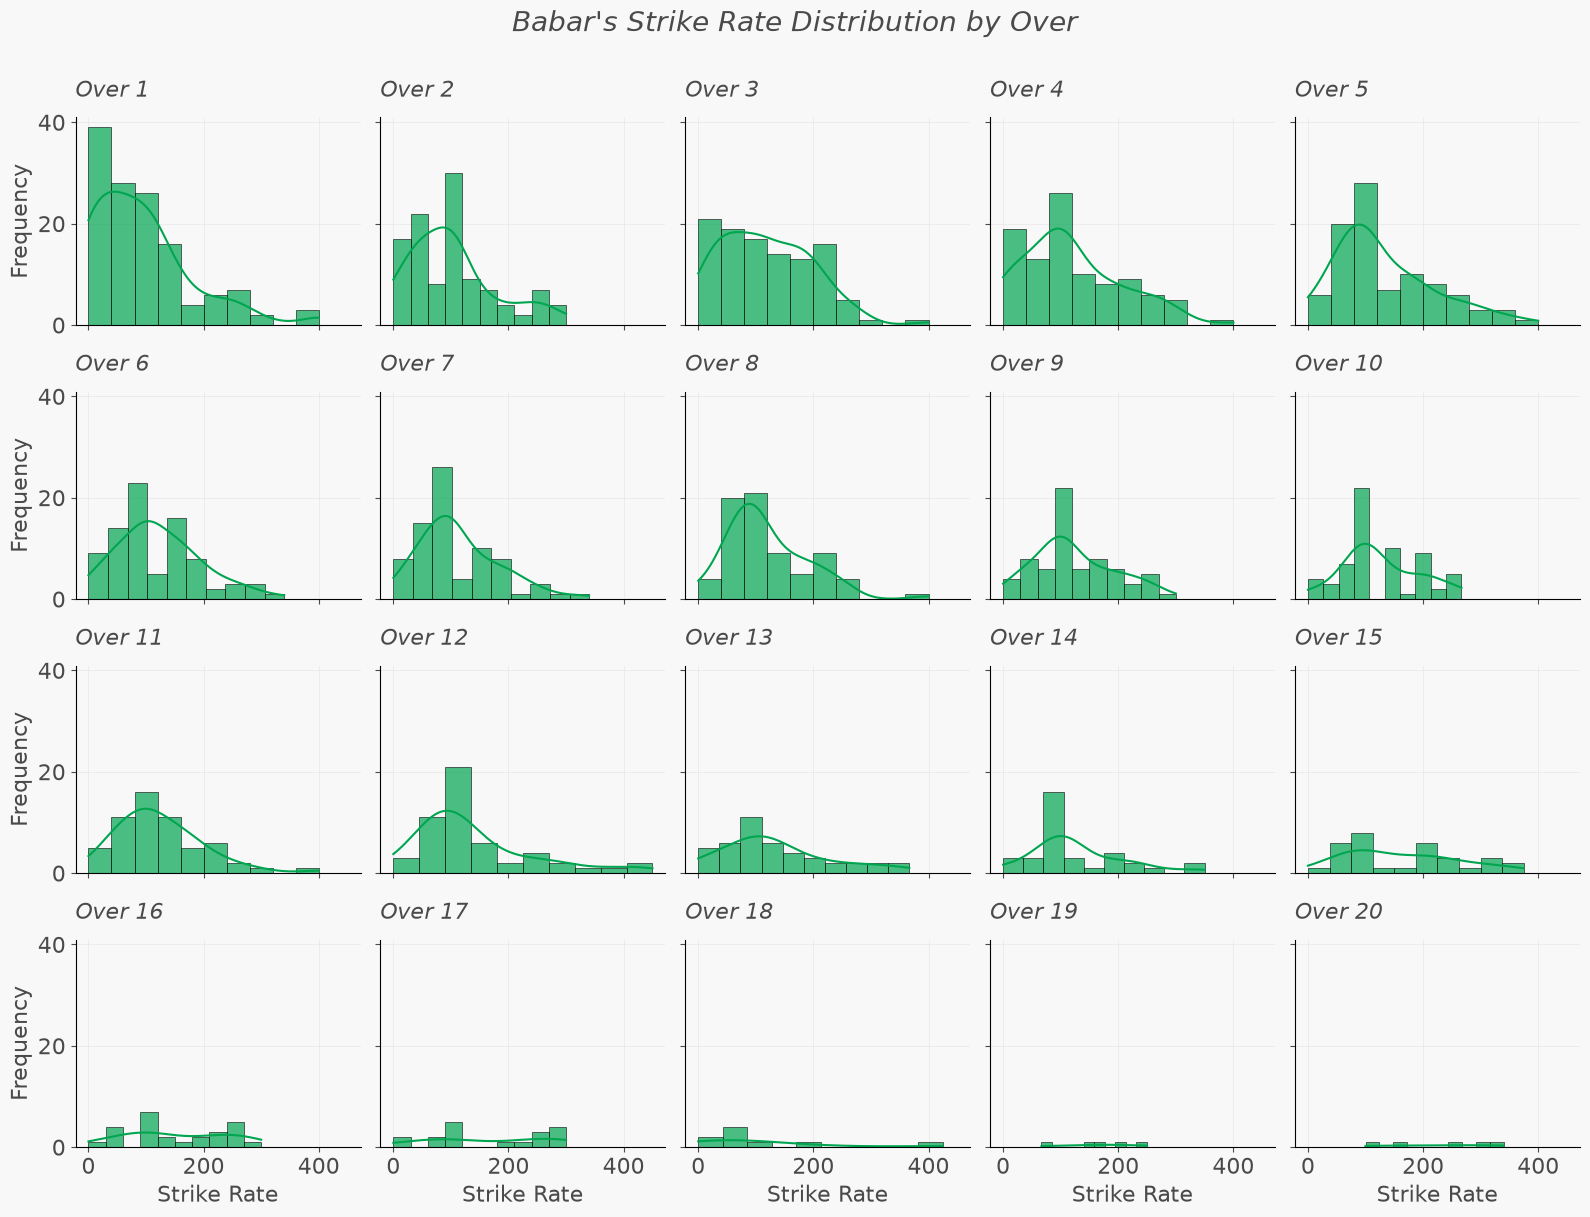

In [25]:
fig, ax = plt.subplots(nrows=4, ncols=5, sharex=True, sharey=True, figsize=(16, 12))

for i, axis in enumerate(ax.flatten()):
    over = i + 1
    data = babar_player_table_t20_set_for_batsman_strike_rate[f'over_{over}'].dropna()
    
    sn.histplot(data, bins=10, kde=True, ax=axis, color='#00A550', alpha=0.7, 
                 linewidth=0.4, line_kws={'color': '#FFD700', 'linewidth': 1.5})
    axis.set_title(f'Over {over}', style='italic', fontsize=16)
    axis.set_xlabel("Strike Rate", fontsize=16)
    axis.set_ylabel("Frequency", fontsize=16)
    axis.tick_params(labelsize=16)

fig.suptitle("Babar's Strike Rate Distribution by Over", style='italic', fontsize=20, y=1.01)
plt.tight_layout()
plt.savefig('E:/Cricket Data/Babar Azam Project Charts/Babar_SR_Distribution_by_Over.png',transparent = True ,dpi=300, bbox_inches='tight')

In [ ]:
pakistan_cities = pd.read_csv(r"pakistan_cities.csv")

In [27]:
home_cities = set(pakistan_cities['city'])

babar_player_table_t20['home/away'] = np.where(
    babar_player_table_t20['city'].isna(),
    None,
    np.where(babar_player_table_t20['city'].isin(home_cities), 'home', 'away')
)

In [28]:
columns_to_drop = babar_player_table_t20.loc[:,'over_1_balls':'over_20_runs'].columns
babar_player_table_t20_balls_overs_sliced = babar_player_table_t20.drop(columns=columns_to_drop)

In [29]:
babar_player_table_t20_runs_overs_sliced = babar_player_table_t20_set_for_batsman.loc[:,'over_1_runs':'over_20_runs']

In [30]:
avg_runs = {}

for i in range(1,21):
    balls_col = f'over_{i}_balls'
    runs_col = f'over_{i}_runs'
    filtered = babar_player_table_t20_set_for_batsman[babar_player_table_t20_set_for_batsman[balls_col]>0]
    avg_runs[f'over_{i}'] = filtered[runs_col].mean()
avg_runs_series = pd.Series(avg_runs)

### Average runs per over
**Takeaway:** Scoring rises the longer he stays at the crease, from roughly 2 runs in his first over to 4–5 in the middle of his innings, with the highest average in the last over. The highest overs rest on few innings, so treat them as indicative.

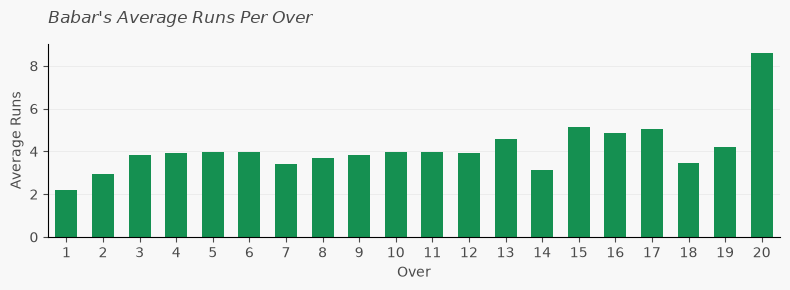

In [31]:
plt.figure(figsize=(8,3))
sn.barplot(x = avg_runs_series.index,y = avg_runs_series.values,width=0.6,color='#00A550', errorbar=None)
plt.xticks(ticks = range(20), labels = range(1,21))
plt.title("Babar's Average Runs Per Over", style='italic')
plt.xlabel('Over')
plt.ylabel('Average Runs')
plt.tight_layout()
plt.savefig('E:/Cricket Data/Babar Azam Project Charts/Babar_Average_Runs_Per_Over.png',dpi = 300,facecolor='#F8F8F8', bbox_inches = 'tight')

In [32]:
avg_str = {}
for i in range(1,21):
    over_col = f'over_{i}'
    filtered = babar_player_table_t20_set_for_batsman_strike_rate[babar_player_table_t20_set_for_batsman_strike_rate[over_col]>0]
    avg_str[f'over_{i}'] = filtered[over_col].mean()

### Average strike rate per over
**Takeaway:** [Write this after you re-run the chart. The expected pattern is a gradual rise in strike rate as the innings progresses, with the last few overs based on few innings.]

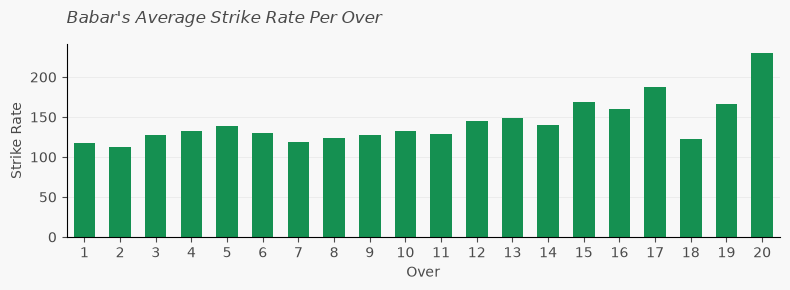

In [33]:
plt.figure(figsize=(8,3))
sn.barplot(data=avg_str, width = 0.6, color = '#00A550')
plt.xticks(ticks=range(20), labels=range(1, 21))
plt.title("Babar's Average Strike Rate Per Over", style='italic')
plt.xlabel('Over')
plt.ylabel('Strike Rate')
plt.tight_layout()

plt.savefig('E:/Cricket Data/Babar Azam Project Charts/Babar_Average_SR_Per_Over.png',dpi = 300,facecolor='#F8F8F8', bbox_inches = 'tight')


In [34]:
babar_player_table_t20_set_for_batsman_chasing_1 = babar_player_table_t20_set_for_batsman[babar_player_table_t20_set_for_batsman['chasing']==1]
babar_player_table_t20_set_for_batsman_chasing_0 =babar_player_table_t20_set_for_batsman[babar_player_table_t20_set_for_batsman['chasing']==0]

In [35]:
babar_player_table_t20_set_for_batsman_chasing_1_power = babar_player_table_t20_set_for_batsman_chasing_1[babar_player_table_t20_set_for_batsman_chasing_1['balls_in_power_play']>0]
babar_player_table_t20_set_for_batsman_chasing_1_middle = babar_player_table_t20_set_for_batsman_chasing_1[babar_player_table_t20_set_for_batsman_chasing_1['balls_in_middle_overs']>0]
babar_player_table_t20_set_for_batsman_chasing_1_death = babar_player_table_t20_set_for_batsman_chasing_1[babar_player_table_t20_set_for_batsman_chasing_1['balls_in_death_overs']>0]
babar_player_table_t20_set_for_batsman_chasing_0_power = babar_player_table_t20_set_for_batsman_chasing_0[babar_player_table_t20_set_for_batsman_chasing_0['balls_in_power_play']>0]
babar_player_table_t20_set_for_batsman_chasing_0_middle = babar_player_table_t20_set_for_batsman_chasing_0[babar_player_table_t20_set_for_batsman_chasing_0['balls_in_middle_overs']>0]
babar_player_table_t20_set_for_batsman_chasing_0_death = babar_player_table_t20_set_for_batsman_chasing_0[babar_player_table_t20_set_for_batsman_chasing_0['balls_in_death_overs']>0]



babar_long_format = {
    'phase' : ['power', 'middle', 'death','power', 'middle', 'death'],
    'situation' :['chasing','chasing','chasing','setting','setting','setting'],
    'avg_runs' : [

        
        babar_player_table_t20_set_for_batsman_chasing_1_power['score_in_power_play'].mean(),
        
        babar_player_table_t20_set_for_batsman_chasing_1_middle['score_in_middle_overs'].mean(),
        
        babar_player_table_t20_set_for_batsman_chasing_1_death['score_in_death_overs'].mean(),
        
        babar_player_table_t20_set_for_batsman_chasing_0_power['score_in_power_play'].mean(),
        
        babar_player_table_t20_set_for_batsman_chasing_0_middle['score_in_middle_overs'].mean(),
        
        babar_player_table_t20_set_for_batsman_chasing_0_death['score_in_death_overs'].mean(),

    ]

}

In [36]:
babar_long_format_df = pd.DataFrame(babar_long_format)

### Runs by phase: chasing vs setting
**Takeaway:** When chasing he scores more in the middle overs (about 30 vs 25 runs) but less in the powerplay (about 12 vs 15) and the death overs (about 9 vs 15). Note that a chase ends as soon as the target is reached, so fewer chasing innings last into the death overs.

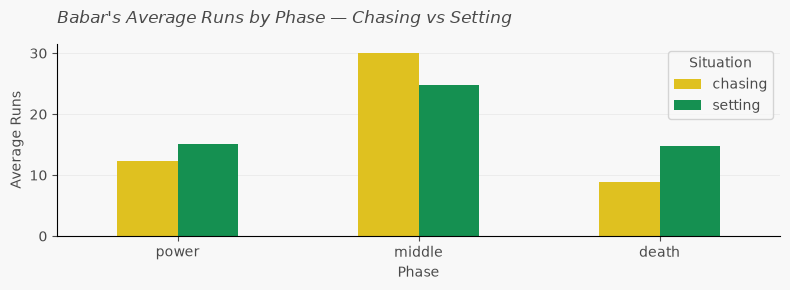

In [37]:
plt.figure(figsize=(8,3))
sn.barplot(data = babar_long_format_df,x = 'phase', y = 'avg_runs',  hue = 'situation', width = 0.5,palette={'chasing': '#FFD700', 'setting': '#00A550'})
plt.title("Babar's Average Runs by Phase — Chasing vs Setting", style='italic')
plt.xlabel('Phase')
plt.ylabel('Average Runs')
plt.legend(title='Situation')
plt.tight_layout()
plt.savefig('E:/Cricket Data/Babar Azam Project Charts/Babar_Average_by_Phase.png', dpi = 300,facecolor='#F8F8F8', bbox_inches = 'tight')

### Score distribution
**Takeaway:** 27 of 131 innings ended on 6 runs or fewer, while a small number above 90 lift the average. The dashed lines mark 30 runs and a half-century. A typical Babar innings is better described by the median (27) than the mean (33).

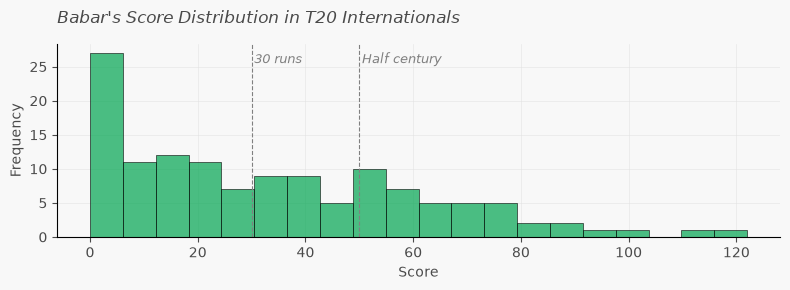

In [38]:
plt.figure(figsize=(8,3))
sn.histplot(data = babar_player_table_t20, x = 'score',color='#00A550', bins = 20, alpha = 0.7, linewidth =0.4)
plt.axvline(x=30, color='grey', linestyle='--', linewidth=0.8)
plt.axvline(x=50, color='grey', linestyle='--', linewidth=0.8)
plt.text(30.5, plt.gca().get_ylim()[1]*0.9, '30 runs', fontsize=9, color='grey', style='italic')
plt.text(50.5, plt.gca().get_ylim()[1]*0.9, 'Half century', fontsize=9, color='grey', style='italic')
plt.title("Babar's Score Distribution in T20 Internationals", style='italic')
plt.xlabel('Score')
plt.ylabel('Frequency')
plt.tight_layout()
plt.savefig('E:/Cricket Data/Babar Azam Project Charts/Babar_Score_Distribution.png',dpi = 300,facecolor='#F8F8F8', bbox_inches = 'tight')


## 5. Context

### Setting vs chasing
**Takeaway:** His median score is roughly 20 when chasing against roughly 34 when setting a target, so he has more low scores when chasing. His highest innings (122) also came in a chase, which is why the means (about 30 vs 37) are closer than the medians. Dashed green line = mean, solid line = median.

C:\Users\HUZAIFA\AppData\Local\Temp\ipykernel_9544\2701329260.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sn.boxplot(data=babar_player_table_t20, x='chasing', y='score', width=0.2,


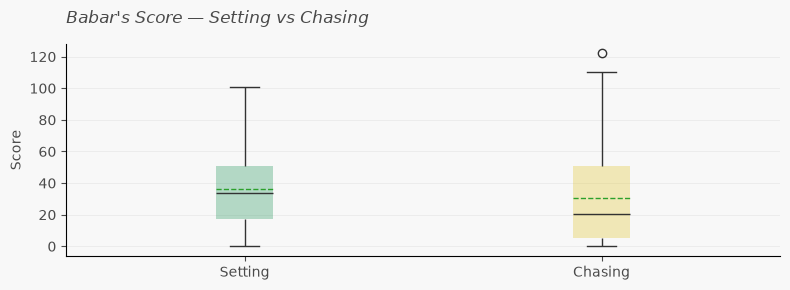

In [39]:
plt.figure(figsize=(8, 3))
sn.boxplot(data=babar_player_table_t20, x='chasing', y='score', width=0.2, 
            boxprops={'alpha': 0.3,'edgecolor':'None'}, gap=0.2, showmeans=True, meanline=True,
            palette={'0': '#00A550', '1': '#FFD700'})
plt.xticks(ticks=[0, 1], labels=['Setting', 'Chasing'])
plt.title("Babar's Score — Setting vs Chasing", style='italic')
plt.xlabel('')
plt.ylabel('Score')
plt.tight_layout()
plt.savefig('E:/Cricket Data/Babar Azam Project Charts/Babar_Chasing_vs_Setting.png',dpi = 300,transparent = True, bbox_inches = 'tight')

In [40]:
babar_against_mean = babar_player_table_t20.groupby(['against'])['score'].agg(['mean', 'count']).reset_index()
babar_against_mean = babar_against_mean.rename(columns={'mean':'score'})
#babar_against_mean = babar_against_mean.sort_values('score', ascending=False).reset_index(drop=True)
order = (babar_against_mean['against'].tolist())

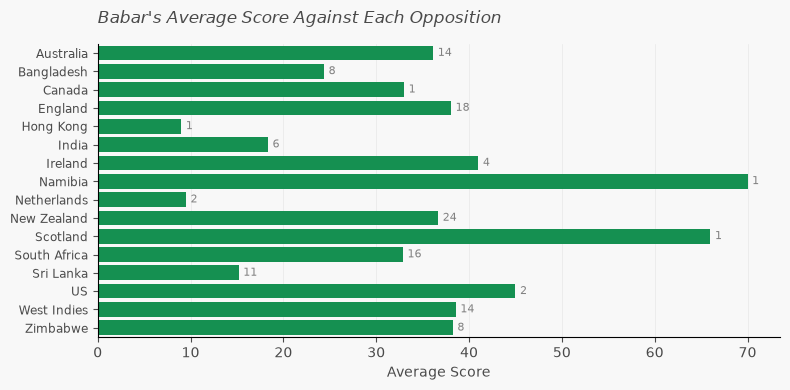

In [42]:
plt.figure(figsize=(8, 4))
sn.barplot(data=babar_against_mean, x='score', y='against',
            color='#00A550',errorbar=None, legend=False,order=order)
for i, (score, count) in enumerate(zip(babar_against_mean['score'], babar_against_mean['count'])):
    plt.text(score + 0.5, i,count, va='center', fontsize=8, color='grey')
plt.title("Babar's Average Score Against Each Opposition", style='italic')
plt.yticks(fontsize = 8.5)
plt.xlabel('Average Score')
plt.ylabel('')
plt.tight_layout()
#plt.savefig('E:/Cricket Data/Babar Azam Project Charts/Babar_Average_SR_Per_Over.png',dpi = 300,facecolor='#F8F8F8', bbox_inches = 'tight')
plt.savefig('E:/Cricket Data/Babar Azam Project Charts/Babar_Avg_vs_Opposition.png', dpi = 300,facecolor='#F8F8F8', bbox_inches = 'tight')



In [43]:
babar_player_table_t20_home_away = babar_player_table_t20.groupby('home/away')

### Home vs away
**Takeaway:** Mean score is almost the same at home and away (about 32), so there is no clear home advantage in the average. The spread differs, with a lower home median. "Home" is defined by city, so Pakistan's home games played in the UAE count as away.

C:\Users\HUZAIFA\AppData\Local\Temp\ipykernel_9544\1593126884.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sn.boxplot(data=babar_player_table_t20, x='home/away', y='score', width=0.2,


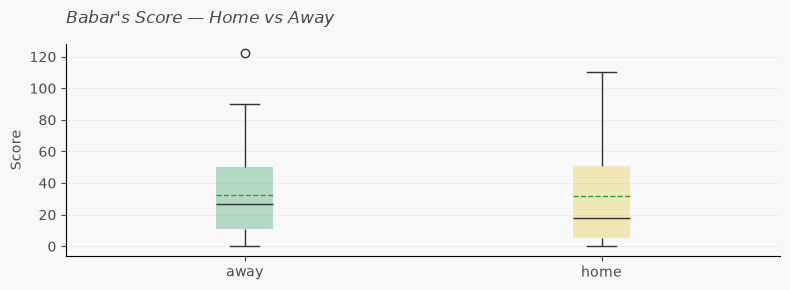

In [45]:
plt.figure(figsize=(8, 3))
sn.boxplot(data=babar_player_table_t20, x='home/away', y='score', width=0.2,
            palette={'home': '#FFD700', 'away': '#00A550'},
            boxprops={'alpha': 0.3, 'edgecolor': 'none'},
            showmeans=True, meanline=True,
            gap=0.2)
plt.title("Babar's Score — Home vs Away", style='italic')
plt.xlabel('')
plt.ylabel('Score')
plt.tight_layout()
plt.savefig('E:/Cricket Data/Babar Azam Project Charts/Babar_Home_vs_Away.png', dpi = 300,transparent=True, bbox_inches = 'tight')

### Win vs loss
**Takeaway:** His mean score is about 36 in wins and 29 in losses, but the medians are nearly the same (about 27–28). The difference comes from big innings in winning games, not from a higher typical score.

C:\Users\HUZAIFA\AppData\Local\Temp\ipykernel_9544\1154812978.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sn.boxplot(data=babar_player_table_t20, x='result', y='score', width=0.2,


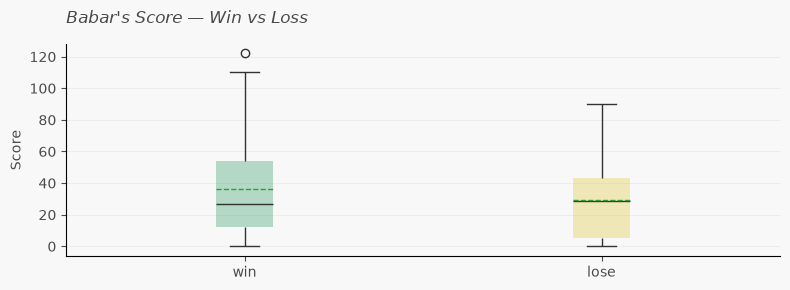

In [46]:
plt.figure(figsize=(8, 3))
sn.boxplot(data=babar_player_table_t20, x='result', y='score', width=0.2,
            palette={'win': '#00A550', 'lose': '#FFD700'},
            boxprops={'alpha': 0.3, 'edgecolor': 'none'},
            showmeans=True, meanline=True,
            gap=0.2)
plt.title("Babar's Score — Win vs Loss", style='italic')
plt.xlabel('')
plt.ylabel('Score')
plt.tight_layout()
plt.savefig('E:/Cricket Data/Babar Azam Project Charts/Babar_Win_vs_Loss.png',dpi = 300,transparent=True, bbox_inches = 'tight')

In [47]:
min_value = babar_player_table_t20_set_for_batsman_chasing_1['required_strike_rate'].min()
max_value = babar_player_table_t20_set_for_batsman_chasing_1['required_strike_rate'].max()

### Actual vs required strike rate when chasing
Each dot is one chase. Points above the dashed diagonal are innings where he scored faster than the rate required at the start of the chase.

**Takeaway:** [Add the share of chases above the line, e.g. "X of Y chases". Compute it with `(df['player\'s_strike_rate'] > df['required_strike_rate']).mean()`.] The cluster of dots at zero is a set of ducks.

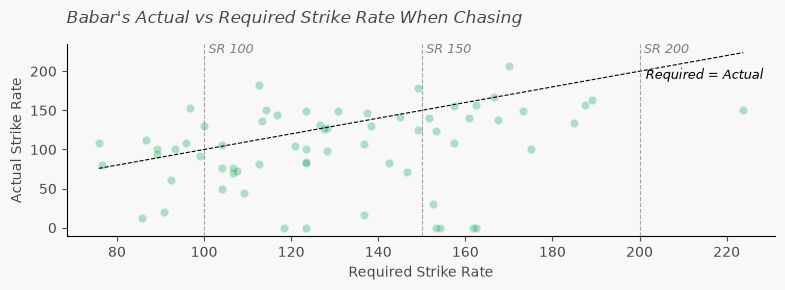

In [48]:
plt.figure(figsize=(8, 3))
plt.grid(False)
sn.scatterplot(data=babar_player_table_t20_set_for_batsman_chasing_1, 
                x='required_strike_rate', y="player's_strike_rate",
                alpha=0.3, color='#00A550')
min_val = babar_player_table_t20_set_for_batsman_chasing_1['required_strike_rate'].min()
max_val = babar_player_table_t20_set_for_batsman_chasing_1['required_strike_rate'].max()
plt.plot([min_val, max_val], [min_val, max_val], '--', color='black', linewidth=0.8)
plt.axvline(x=100, color='grey', linestyle='--', linewidth=0.8, alpha=0.7)
plt.axvline(x=150, color='grey', linestyle='--', linewidth=0.8, alpha=0.7)
plt.axvline(x=200, color='grey', linestyle='--', linewidth=0.8, alpha=0.7)
plt.text(101, plt.gca().get_ylim()[1]*0.95, 'SR 100', fontsize=9, color='grey', style='italic')
plt.text(151, plt.gca().get_ylim()[1]*0.95, 'SR 150', fontsize=9, color='grey', style='italic')
plt.text(201, plt.gca().get_ylim()[1]*0.95, 'SR 200', fontsize=9, color='grey', style='italic')
plt.text(max_val*0.90, max_val*0.85, 'Required = Actual', fontsize=9, color='black', style='italic')
plt.title("Babar's Actual vs Required Strike Rate When Chasing", style='italic')
plt.xlabel('Required Strike Rate')
plt.ylabel('Actual Strike Rate')
plt.tight_layout()
plt.savefig('E:/Cricket Data/Babar Azam Project Charts/Babar_SR_Chasing.png', dpi = 300,transparent = True, bbox_inches = 'tight')

In [49]:
babar_player_table_t20_pivot = babar_player_table_t20.groupby(['against', 'chasing'])['score'].mean().reset_index().pivot(index = 'against', columns = 'chasing', values = 'score')

In [50]:
babar_player_table_t20_pivot.columns.name = None
babar_player_table_t20_pivot = babar_player_table_t20_pivot.rename(columns={0: 'Setting', 1: 'Chasing'})

### By opposition
Numbers at the end of each bar are the number of innings.

**Takeaway:** Among teams he has faced 10 or more times, Sri Lanka is the clear low (average 15.2 over 11 innings). England (38.1), West Indies (38.6), New Zealand (36.7) and Australia (36.1) sit in the mid-to-high 30s, and South Africa is 32.9. Teams faced only once or twice (Namibia, Scotland, Canada, Hong Kong) are single data points, not patterns. The heatmap splits the same averages by setting and chasing; with so few innings per cell, read it as exploratory.

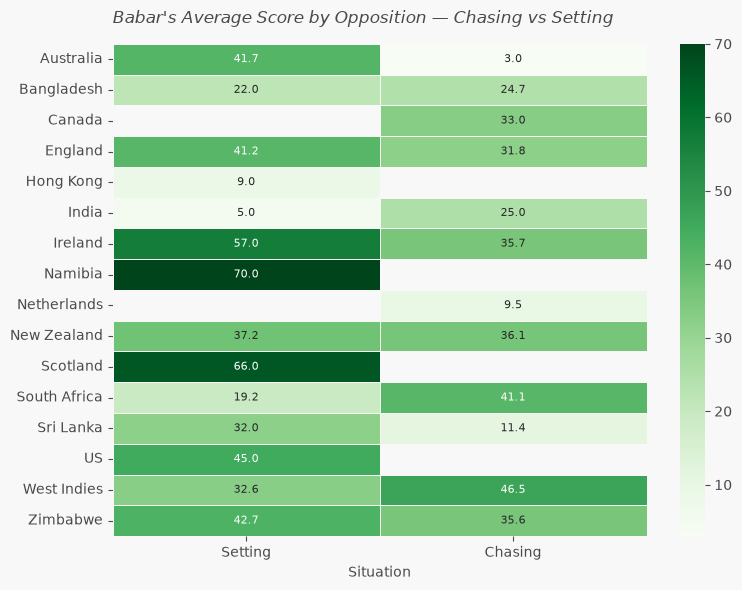

In [51]:
plt.figure(figsize=(8, 6))
plt.grid(False)
sn.heatmap(babar_player_table_t20_pivot, annot=True, fmt='.1f',
            cmap='Greens', linewidths=0.5, linecolor='#F8F8F8',
            annot_kws={'size': 8})
plt.title("Babar's Average Score by Opposition — Chasing vs Setting", style='italic')
plt.xlabel('Situation')
plt.ylabel('')
plt.tight_layout()
plt.savefig('E:/Cricket Data/Babar Azam Project Charts/Babar_Heatmap.png',dpi = 300,facecolor='#F8F8F8', bbox_inches = 'tight')

### Contribution as a share of the target
**Takeaway:** He rarely carries a chase alone. [X] of the chasing innings contributed under 3% of the target, and none exceeded about 60%.

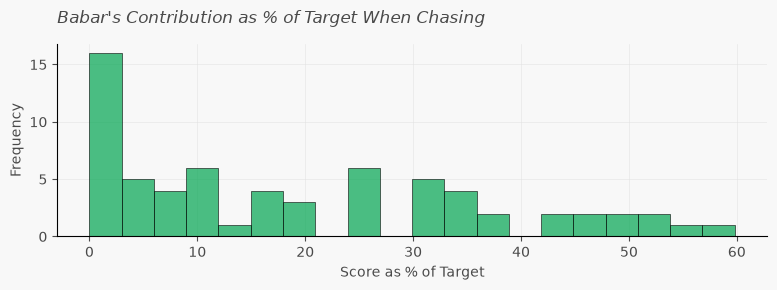

In [52]:
plt.figure(figsize=(8, 3))
sn.histplot(data=babar_player_table_t20_set_for_batsman_chasing_1, 
             x='score_as_percent_of_target', bins=20, kde=False,
             color='#00A550', alpha = 0.7, linewidth =0.4)
plt.title("Babar's Contribution as % of Target When Chasing", style='italic')
plt.xlabel('Score as % of Target')
plt.ylabel('Frequency')
plt.tight_layout()
plt.savefig('E:/Cricket Data/Babar Azam Project Charts/Babar_Score_Percent_Target.png', dpi=300, bbox_inches='tight', facecolor='#F8F8F8')

In [53]:
babar_player_table_t20['year'] = babar_player_table_t20['dates'].dt.year
babar_player_table_t20_groupedby_dates = babar_player_table_t20.groupby('year')['score'].mean().reset_index()

## 6. Career trend

### Average score by year
**Takeaway:** His yearly average peaked at about 47 in 2018 and 46 in 2020 and has declined since, to about 24 in 2026. 2016 and 2023 have only 4 innings each, and 2026 has 7, so single years are noisy. The longer downward direction matters more than any one point.

### Innings per year
Shown so the yearly averages can be read with their sample sizes: 25 innings in 2021 and 2022, 23 in 2024, and as few as 4 in 2016 and 2023.

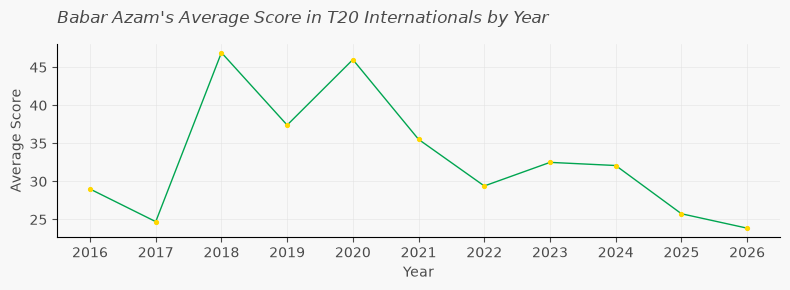

In [54]:
plt.figure(figsize=(8, 3))
sn.lineplot(data=babar_player_table_t20_groupedby_dates, x='year', y='score', 
             color='#00A550', alpha=1, marker='o', markerfacecolor='#FFD700',
             markeredgecolor='#FFD700', linewidth=1)
plt.setp(plt.gca().lines[0], markersize=3)
plt.title("Babar Azam's Average Score in T20 Internationals by Year", style='italic')
plt.xlabel('Year')
plt.ylabel('Average Score')
plt.xticks(babar_player_table_t20_groupedby_dates['year'])
plt.tight_layout()
plt.savefig('E:/Cricket Data/Babar Azam Project Charts/Babar_Trend_by_Year.png', dpi=300, bbox_inches='tight', transparent=True)

In [55]:
babar_player_table_t20_dates_into_year = babar_player_table_t20.copy()
babar_player_table_t20_dates_into_year['dates'] = babar_player_table_t20_dates_into_year['dates'].dt.year

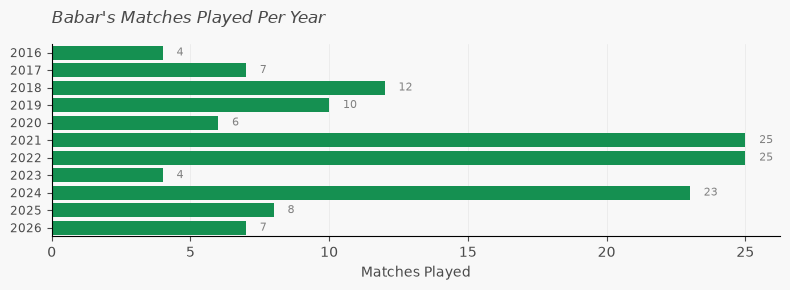

In [56]:
plt.figure(figsize=(8,3))

# 1. Generate the horizontal countplot (using 'year')
sn.countplot(data=babar_player_table_t20_dates_into_year, y='year', color='#00A550', legend=False)

# 2. Get the correct, ordered counts matching the plot's Y-axis categories
# This counts how many matches occurred in each year, sorted chronologically
year_counts = babar_player_table_t20_dates_into_year['year'].value_counts().sort_index()

# 3. Add text labels next to the bars using the right coordinates
for i, (year, count) in enumerate(year_counts.items()):
    # X = count + 0.5 (just past the end of the bar)
    # Y = i (the sequential index of the horizontal bar)
    plt.text(count + 0.5, i, str(count), va='center', ha='left', fontsize=8, color='grey')

plt.title("Babar's Matches Played Per Year", style='italic')
plt.yticks(fontsize=8.5)
plt.xlabel('Matches Played')
plt.ylabel('')
plt.tight_layout()

plt.savefig('E:/Cricket Data/Babar Azam Project Charts/Babar_match_played_per_year.png', dpi=300, transparent=True, bbox_inches='tight')


### Babar balls over run regressiom

In [57]:
from scipy import stats
res = stats.linregress(babar_player_table_t20['balls'],babar_player_table_t20['score'])
slope = res.slope
intercept = res.intercept
r_squared = res.rvalue**2
print(f'Slope: {slope}')
print(f'Intercept: {intercept}')
print(f'R-squared: {r_squared}')

Slope: 1.5275478682423262
Intercept: -6.434642982491091
R-squared: 0.9073443593242864


In [58]:
babar_player_table_t20['score'].sum()/babar_player_table_t20['balls'].sum()

np.float64(1.2803519061583577)

## 7. Score vs balls faced
A simple linear regression of score on balls faced:

**Score ≈ 1.53 × balls − 6.43, R² = 0.91**

**Takeaway:** Each extra ball faced is associated with about 1.5 more runs, and balls faced explains about 91% of the variation in score. This is expected, because score equals strike rate times balls faced. The useful reading is the residual spread: innings far from the line are the ones where he scored unusually fast or slow for the time he spent batting. His overall rate across all innings is 1.28 runs per ball (strike rate 128).

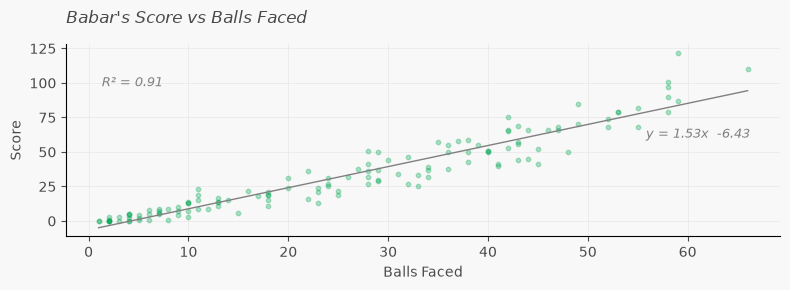

In [59]:
plt.figure(figsize=(8, 3))
sn.regplot(data=babar_player_table_t20, x='balls', y='score', ci  =None,
            scatter_kws={'alpha': 0.3, 'color': '#00A550', 's' : 10},
            line_kws={'color': 'grey', 'linewidth': 1})
x_mid = babar_player_table_t20['balls'].mean()
y_mid = slope * x_mid + intercept
plt.text(x_mid +35, y_mid + 27, f'y = {slope:.2f}x  {intercept:.2f}', 
         fontsize=9, color='grey', style='italic', ha='center')
plt.text(0.05, 0.78, f'R² = {r_squared:.2f}', 
         transform=plt.gca().transAxes, fontsize=9, color='grey', style='italic')
plt.title("Babar's Score vs Balls Faced", style='italic')
plt.xlabel('Balls Faced')
plt.ylabel('Score')
plt.tight_layout()
plt.savefig('E:/Cricket Data/Babar Azam Project Charts/Babar_Score_vs_Balls.png', dpi=300, bbox_inches='tight', transparent = True)

In [60]:
total_score = babar_player_table_t20['score'].mean()
total_balls = babar_player_table_t20['balls'].mean()
round(total_score / total_balls,3)

np.float64(1.28)

## 8. Conclusions

1. **Typical vs peak:** A typical innings is modest (median 27); a few large scores lift the mean to 33.
2. **Chasing:** His median score is clearly lower when chasing (about 20 vs 34), with more low scores in chases.
3. **Wins vs losses:** The gap in means comes from big scores in wins, since medians are similar.
4. **Venue:** No clear home advantage in mean score.
5. **Opposition:** Sri Lanka is the standout low among teams faced 10+ times; most other opponents sit in the 32–39 range.
6. **Within an innings:** Scoring rises the longer he bats.
7. **Career trend:** His yearly average has fallen from about 47 (2018) to about 24 (2026).

## Limitations
- One player, descriptive analysis only; nothing here shows *why* a pattern exists.
- Small samples for many splits (opposition, year, home/away).
- Chase innings end when the target is reached, which affects late-phase comparisons.
- "Average" is mean score per innings and ignores not-outs, so it is not a conventional batting average.
- Per-over charts index overs by his own innings, not match overs.

## Next steps
- Add significance tests and confidence intervals for the chasing/setting and win/loss gaps.
- Compare against other batters from the same era.
- Model strike rate on context (phase, innings situation, opposition) rather than raw score.